In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import seaborn as sns
from matplotlib.ticker import MaxNLocator
import warnings
warnings.filterwarnings("ignore")

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",   # Prefer if installed
        "Liberation Serif",  # Common on Ubuntu / Debian
        "Nimbus Roman",      # Common with TeX / Ghostscript
        "DejaVu Serif"       # Matplotlib fallback
    ],
    "mathtext.fontset": "stix",       # Math symbols closer to Times
    "axes.unicode_minus": False,
})

import os
import sys

# --- Make project root importable so `from Utils...` works ---
project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if project_root not in sys.path:
    sys.path.append(project_root)

import torch
from Utils.context_fid import Context_FID
from Utils.predictive_metric import predictive_score_metrics
import Utils.extreme_anomaly_metric as extreme_anomaly_metric
from Utils.extreme_anomaly_metric import (
    extreme_anomaly_score_metrics,
    extreme_reconstruction_score_metrics,
)


pd.set_option("display.max_rows", None)         # Show all rows
pd.set_option("display.max_columns", None)      # Show all columns
pd.set_option("display.width", None)            # No fixed-width wrap
pd.set_option("display.max_colwidth", None)     # Do not truncate cell values
pd.set_option("display.expand_frame_repr", False)  # Prefer single-line frames

In [31]:
# ---------------------------------------------------------------------------
# dataset_name | threshold (unnormalized) | tail
# -------------|---------------------------|------------------
# toyexample   | 0.3711                    | upper
# temperature  | 8.30                      | lower
# precipitation| 1015.0                    | upper 
# Electricity  | 2.4905                    | upper 
# ECG          | 0.3205                    | upper 
# transportation | 0.097                   | upper 

# Pick one row: set dataset_name, threshold, and tail together

dataset_name = "toyexample"  
threshold = 0.3711
tail = "upper"

In [7]:
ori = np.load(f'OUTPUT/{dataset_name}_SynEnergy/origin_data_unnorm_{dataset_name}_SynEnergy.npy')
gen = np.load(f'OUTPUT/{dataset_name}_SynEnergy/generate_data_unnorm_{dataset_name}_SynEnergy.npy')
ori = ori[:, :, 0][:, :, np.newaxis]
gen = gen[:, :, 0][:, :, np.newaxis]
N = min(ori.shape[0], gen.shape[0])
ori = ori[:N]
gen = gen[:N]

## Performance Visualization

In [18]:
def visualize_samples(ori_data, gen_data, N=10, threshold=None, seed=None, tail="upper"):
    """
    Draw two figures from N random samples of original and generated data.
    
    Parameters:
    -----------
    ori_data : np.ndarray, shape (num_samples, seq_length, 1)
        Original data
    gen_data : np.ndarray, shape (num_samples, seq_length, 1)
        Generated data
    N : int, default=10
        Number of samples to draw
    threshold : float, optional
        Threshold; with tail highlights values > or < threshold
    seed : int, optional, default=None
        Random seed; None gives different draws each call.
        Integer seed makes results reproducible.
    tail : str, default "upper"
        "upper": upper tail, red above threshold (original behavior);
        "lower": lower tail, red below threshold.
    """
    tail = str(tail).strip().lower()
    if tail not in ("upper", "lower"):
        raise ValueError('tail must be "upper" or "lower"')

    if seed is not None:
        np.random.seed(seed)
    
    # Ensure 3D shape
    if ori_data.ndim == 2:
        ori_data = ori_data[:, :, np.newaxis]
    if gen_data.ndim == 2:
        gen_data = gen_data[:, :, np.newaxis]
    
    # Random N indices
    num_samples = min(ori_data.shape[0], gen_data.shape[0])
    N = min(N, num_samples)
    selected_indices = np.random.choice(num_samples, size=N, replace=False)
    
    # Selected samples
    ori_selected = ori_data[selected_indices, :, 0]  # (N, seq_length)
    gen_selected = gen_data[selected_indices, :, 0]   # (N, seq_length)
    
    seq_length = ori_selected.shape[1]
    time_steps = np.arange(seq_length)

    def _extreme_mask(values):
        if threshold is None:
            return None
        return values > threshold if tail == "upper" else values < threshold
    
    # Two figures
    fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
    
    # Fig 1: original
    ax1 = axes[0]
    for i in range(N):
        values = ori_selected[i, :]
        mask_ext = _extreme_mask(values)
        if mask_ext is not None:
            ax1.plot(time_steps, values, alpha=0.6, linewidth=1.5, color='blue', label='Original' if i == 0 else '')
            if np.any(mask_ext):
                ax1.plot(time_steps[mask_ext], values[mask_ext], 'ro', markersize=4, alpha=0.8)
        else:
            ax1.plot(time_steps, values, alpha=0.6, linewidth=1.5, color='blue', label='Original' if i == 0 else '')
    
    if threshold is not None:
        ax1.axhline(y=threshold, color='red', linestyle='--', linewidth=2, alpha=0.7,
                    label=f'Threshold={threshold} ({tail})')
    
    ax1.set_xlabel('Time Step', fontsize=12)
    ax1.set_ylabel('Value', fontsize=12)
    ax1.set_title(f'Original Data (N={N} random samples)', fontsize=20, fontweight='bold')
    ax1.grid(True, alpha=0.3)
    ax1.legend(fontsize=20)
    
    # Fig 2: generated
    ax2 = axes[1]
    for i in range(N):
        values = gen_selected[i, :]
        mask_ext = _extreme_mask(values)
        if mask_ext is not None:
            ax2.plot(time_steps, values, alpha=0.6, linewidth=1.5, color='green', label='Generated' if i == 0 else '')
            if np.any(mask_ext):
                ax2.plot(time_steps[mask_ext], values[mask_ext], 'ro', markersize=4, alpha=0.8)
        else:
            ax2.plot(time_steps, values, alpha=0.6, linewidth=1.5, color='green', label='Generated' if i == 0 else '')
    
    if threshold is not None:
        ax2.axhline(y=threshold, color='red', linestyle='--', linewidth=2, alpha=0.7,
                    label=f'Threshold={threshold} ({tail})')
    
    ax2.set_xlabel('Time Step', fontsize=12)
    ax2.set_ylabel('Value', fontsize=12)
    ax2.set_title(f'Generated Data (N={N} random samples)', fontsize=20, fontweight='bold')
    ax2.grid(True, alpha=0.3)
    ax2.legend(fontsize=20)
    
    plt.tight_layout()
    plt.show()
    
    if threshold is not None:
        if tail == "upper":
            ori_ext = np.sum(ori_selected > threshold)
            gen_ext = np.sum(gen_selected > threshold)
            label = "above"
        else:
            ori_ext = np.sum(ori_selected < threshold)
            gen_ext = np.sum(gen_selected < threshold)
            label = "below"

In [13]:
def visualization_distribution(ori_data, generated_data, kde_xlim=None):
    """KDE visualization in a 1x3 grid:
       Col1: Original, Col2: Synthetic, Col3: Overlay
    """

    ori_data = np.asarray(ori_data)
    generated_data = np.asarray(generated_data)

    # (no, seq_len): each sample -> mean over feature dim
    prep_data = np.mean(ori_data, axis=2)
    prep_data_hat = np.mean(generated_data, axis=2)

    flat_ori = prep_data.reshape(-1).astype(np.float64)
    flat_hat = prep_data_hat.reshape(-1).astype(np.float64)

    fig, axes = plt.subplots(1, 3, figsize=(18, 4))
    titles = ["Original Data", "Generated Data", "Overlay"]

    # Original
    sns.kdeplot(flat_ori, linewidth=3, ax=axes[0])
    axes[0].set_title(f"KDE | {titles[0]}",fontsize = 20)
    axes[0].set_xlabel("Data Value")
    axes[0].set_ylabel("Density")

    # Synthetic
    sns.kdeplot(flat_hat, linewidth=3, linestyle="--", ax=axes[1])
    axes[1].set_title(f"KDE | {titles[1]}",fontsize = 20)
    axes[1].set_xlabel("Data Value")
    axes[1].set_ylabel("Density")

    # Overlay
    sns.kdeplot(flat_ori, linewidth=3, ax=axes[2], label="Original Data")
    sns.kdeplot(flat_hat, linewidth=3, linestyle="--", ax=axes[2], label="Generated Data")
    axes[2].set_title(f"KDE | {titles[2]}",fontsize = 20)
    axes[2].set_xlabel("Data Value")
    axes[2].set_ylabel("Density")
    axes[2].legend(frameon=False,fontsize = 20)

    if kde_xlim is not None:
        for ax in axes:
            ax.set_xlim(kde_xlim)

    plt.tight_layout()
    plt.show()
    plt.close()

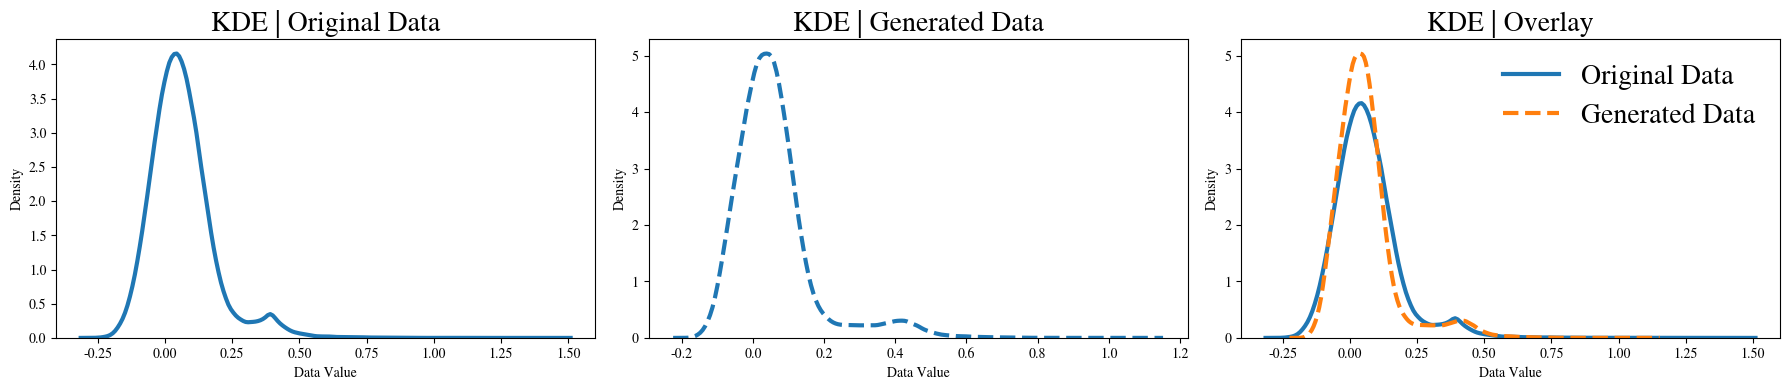

In [32]:
visualization_distribution(ori, gen)

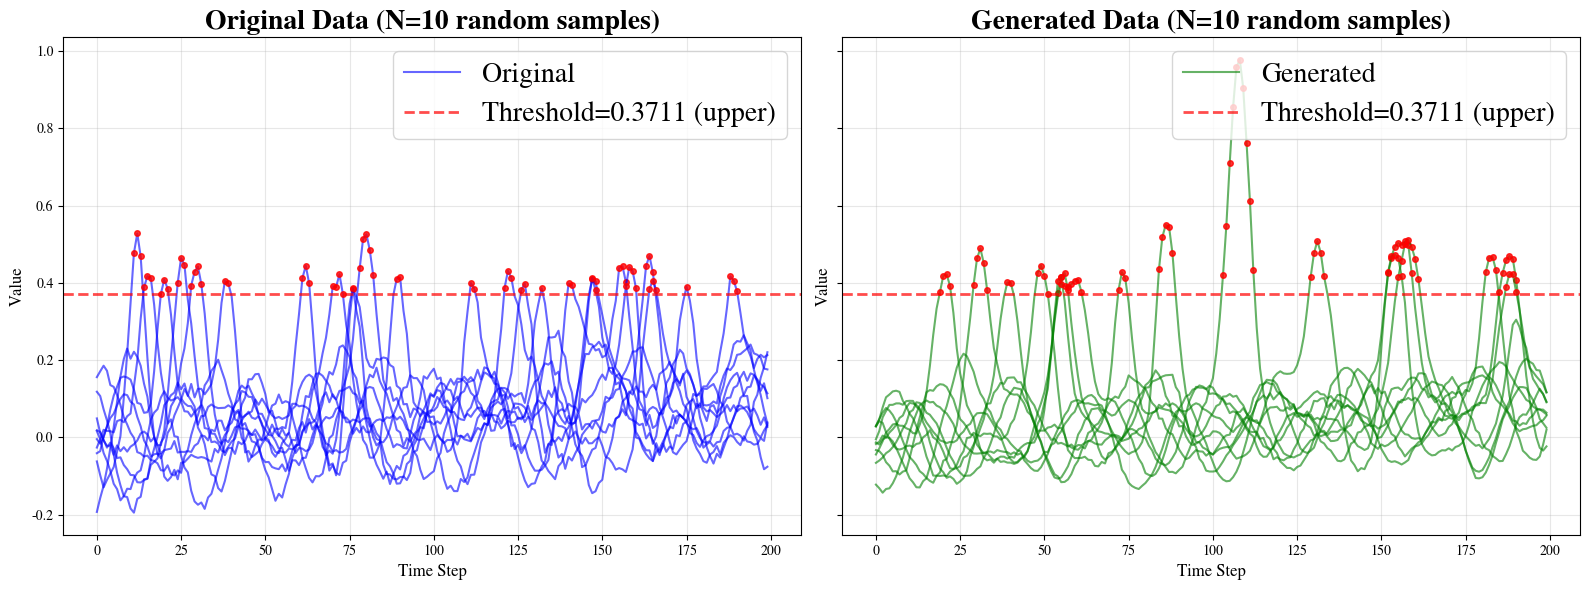

In [19]:
visualize_samples(ori, gen, N=10, threshold=threshold, tail = tail)

## Metrics for Overall Distribution

In [20]:
import numpy as np
from scipy.stats import wasserstein_distance, ks_2samp, kurtosis
from scipy.spatial.distance import jensenshannon

def dist_wasserstein_flat(ori, gen):
    """1D Wasserstein on flattened samples."""
    ori = np.asarray(ori).reshape(-1).astype(np.float64)
    gen = np.asarray(gen).reshape(-1).astype(np.float64)
    return float(wasserstein_distance(ori, gen))

def dist_ks_flat(ori, gen):
    """KS statistic after flattening (returns statistic)."""
    ori = np.asarray(ori).reshape(-1).astype(np.float64)
    gen = np.asarray(gen).reshape(-1).astype(np.float64)
    stat, pval = ks_2samp(ori, gen)
    return float(stat), float(pval)

def dist_js_flat(ori, gen, bins=50):
    """Histogram estimate on flattened data; JS divergence in [0,1]."""
    ori = np.asarray(ori).reshape(-1).astype(np.float64)
    gen = np.asarray(gen).reshape(-1).astype(np.float64)
    lo, hi = min(ori.min(), gen.min()), max(ori.max(), gen.max())
    if hi <= lo:
        return 0.0
    p, _ = np.histogram(ori, bins=bins, range=(lo, hi), density=True)
    q, _ = np.histogram(gen, bins=bins, range=(lo, hi), density=True)
    p, q = p + 1e-10, q + 1e-10
    p, q = p / p.sum(), q / q.sum()
    return float(jensenshannon(p, q))

def dist_mmd_rbf(ori, gen, sigma=None, n_repeats=5):
    ori_full = np.asarray(ori).reshape(ori.shape[0], -1).astype(np.float64)
    gen_full = np.asarray(gen).reshape(gen.shape[0], -1).astype(np.float64)
    max_n = 10000
    mmds = []
    for _ in range(n_repeats):
        rng = np.random.default_rng()
        ori = ori_full
        gen = gen_full
        if ori.shape[0] > max_n:
            idx = rng.choice(ori.shape[0], size=max_n, replace=False)
            ori = ori[idx]
        if gen.shape[0] > max_n:
            idx = rng.choice(gen.shape[0], size=max_n, replace=False)
            gen = gen[idx]
        n1, n2 = ori.shape[0], gen.shape[0]
        def rbf(X, Y, s):
            XY = np.dot(X, Y.T)
            XX = np.sum(X**2, axis=1)[:, None]
            YY = np.sum(Y**2, axis=1)[None, :]
            return np.exp(-(XX + YY - 2 * XY) / (2 * s**2))
        sig = sigma
        if sig is None:
            n_sub = min(500, ori.shape[0])
            rng_sigma = np.random.default_rng()
            idx = rng_sigma.choice(ori.shape[0], size=n_sub, replace=False)
            ori_sub = ori[idx]
            dists = np.linalg.norm(ori_sub[:, None, :] - ori_sub[None, :, :], axis=2)
            sig = np.median(dists)
            sig = max(sig, 1e-6)
        Koo = rbf(ori, ori, sig)
        Kgg = rbf(gen, gen, sig)
        Kog = rbf(ori, gen, sig)
        mmd2 = Koo.mean() + Kgg.mean() - 2 * Kog.mean()
        mmds.append(float(np.sqrt(max(mmd2, 0.0))))
    return float(np.mean(mmds))

def _check_ts_shape(ori, gen):
    ori = np.asarray(ori).astype(np.float64)
    gen = np.asarray(gen).astype(np.float64)
    if ori.ndim == 2:
        ori = ori[..., np.newaxis]
    if gen.ndim == 2:
        gen = gen[..., np.newaxis]
    if ori.ndim != 3 or gen.ndim != 3:
        raise ValueError("ori and gen must have shape (N, T, C) or (N, T)")
    if ori.shape[1] != gen.shape[1] or ori.shape[2] != gen.shape[2]:
        raise ValueError("ori and gen must have the same T and C")
    return ori, gen


def _acf_at_lag(x, lag):
    """Sample ACF at lag (demeaned, unit variance)."""
    x = np.asarray(x, dtype=np.float64).ravel()
    t = len(x)
    if lag < 1 or t < lag + 2:
        return np.nan
    x = x - x.mean()
    num = np.dot(x[:-lag], x[lag:])
    den = np.dot(x, x)
    if den <= 1e-12:
        return np.nan
    return float(num / den)


def dist_acd(ori, gen, max_lag=50):
    """ACD: per-lag mean |sample ACF(ori)-ACF(gen)| over N×C series, averaged over lags. No per-sample pairing."""
    ori, gen = _check_ts_shape(ori, gen)
    _, t, c = ori.shape
    m = min(max_lag, max(0, t - 2))
    if m < 1:
        return 0.0
    diffs = []
    for lag in range(1, m + 1):
        ao, ag = [], []
        for i in range(ori.shape[0]):
            for k in range(c):
                r = _acf_at_lag(ori[i, :, k], lag)
                if np.isfinite(r):
                    ao.append(r)
        for i in range(gen.shape[0]):
            for k in range(c):
                r = _acf_at_lag(gen[i, :, k], lag)
                if np.isfinite(r):
                    ag.append(r)
        if not ao or not ag:
            continue
        diffs.append(abs(np.mean(ao) - np.mean(ag)))
    return float(np.mean(diffs)) if diffs else 0.0


def dist_kd(ori, gen):
    """KD: |excess kurtosis(Fisher) diff after flattening.|"""
    ori = np.asarray(ori).astype(np.float64).ravel()
    gen = np.asarray(gen).astype(np.float64).ravel()
    ko = float(kurtosis(ori, fisher=True, bias=False))
    kg = float(kurtosis(gen, fisher=True, bias=False))
    if not np.isfinite(ko):
        ko = 0.0
    if not np.isfinite(kg):
        kg = 0.0
    return float(abs(ko - kg))


In [21]:
def compute_distribution_distance(ori, gen, bins=50):
    """
    Distance between ori and gen distributions.
    
    Parameters
    ----------
    ori : np.ndarray
        Original distribution, shape (N, T, 1) or (N, T)
    gen : np.ndarray
        Generated distribution, shape (N, T, 1) or (N, T)
    bins : int, default=50
        Histogram bins for JS estimate
    
    Returns
    -------
    dict
        Includes Wasserstein, KS_stat, JS, MMD, ACD.
        ACD = dist_acd(ori, gen) + 0.5 * Wasserstein (same as key Wasserstein).
    """
    ori = np.asarray(ori)
    gen = np.asarray(gen)
    
    w = dist_wasserstein_flat(ori, gen)
    ks_stat, ks_p = dist_ks_flat(ori, gen)
    js = dist_js_flat(ori, gen, bins=bins)
    mmd = dist_mmd_rbf(ori, gen, n_repeats = 20)
    acd = dist_acd(ori, gen) + 0.5 * w
    kd = dist_kd(ori, gen)
    
    return {
        "Wasserstein": w,
        "KS_stat": ks_stat,
        "JS": js,
        "MMD": mmd,
        "ACD": acd,
    }


In [22]:
compute_distribution_distance(ori, gen, bins=50)

{'Wasserstein': 0.014361041563985499,
 'KS_stat': 0.07678000000000007,
 'JS': 0.11062241129099265,
 'MMD': 0.04459308174560124,
 'ACD': 0.050457855533498006}

## Metrics for Extreme Generation

In [23]:
import numpy as np
from scipy.stats import wasserstein_distance
from scipy.spatial.distance import jensenshannon


def _align_same_shape(ori, gen):
    """ori and gen must share shape (N, T, C); do not truncate N."""
    ori = np.asarray(ori).astype(np.float64)
    gen = np.asarray(gen).astype(np.float64)
    if ori.ndim != 3 or gen.ndim != 3:
        raise ValueError("ori and gen must both have shape (N, T, C)")
    if ori.shape != gen.shape:
        raise ValueError("ori and gen must have identical shape (N, T, C)")
    return ori, gen


def _make_threshold_array(x, threshold):
    thr = np.asarray(threshold, dtype=np.float64)
    if thr.ndim == 0:
        return np.full_like(x, float(thr), dtype=np.float64)
    return np.broadcast_to(thr, x.shape).astype(np.float64)


def _normalize_tail(tail):
    t = str(tail).strip().lower()
    if t not in ("upper", "lower"):
        raise ValueError('tail must be "upper" or "lower"')
    return t


def _extreme_mask(x, thr, tail):
    """Elementwise mask: upper x>thr, lower x<thr."""
    tail = _normalize_tail(tail)
    x = np.asarray(x, dtype=np.float64)
    thr = np.asarray(thr, dtype=np.float64)
    if tail == "upper":
        return x > thr
    return x < thr


def _extract_events_1d(x, thr, tail="upper"):
    """
    Returns list of event dicts:
    {
        'start': int,
        'end': int,
        'duration': int,
        'peak': float,
        'peak_idx': int
    }
    upper: contiguous x > thr; peak at segment maximum;
    lower: contiguous x < thr; peak at segment minimum.
    """
    tail = _normalize_tail(tail)
    x = np.asarray(x).astype(np.float64)
    thr = np.asarray(thr).astype(np.float64)

    mask = _extreme_mask(x, thr, tail)
    events = []
    tlen = len(x)
    i = 0

    while i < tlen:
        if not mask[i]:
            i += 1
            continue

        s = i
        while i + 1 < tlen and mask[i + 1]:
            i += 1
        e = i

        seg = x[s:e + 1]
        if tail == "upper":
            rel_peak_idx = int(np.argmax(seg))
        else:
            rel_peak_idx = int(np.argmin(seg))
        peak_idx = s + rel_peak_idx
        peak = float(seg[rel_peak_idx])

        events.append({
            "start": int(s),
            "end": int(e),
            "duration": int(e - s + 1),
            "peak": peak,
            "peak_idx": int(peak_idx),
        })
        i += 1

    return events


def _flatten_extreme_values_ch0(x, threshold, tail="upper"):
    """Channel 0 only: flatten values in extreme region."""
    tail = _normalize_tail(tail)
    x = np.asarray(x, dtype=np.float64)
    thr = _make_threshold_array(x, threshold)
    m = _extreme_mask(x[:, :, 0], thr[:, :, 0], tail)
    return x[:, :, 0][m].astype(np.float64).ravel()


def _pooled_histogram_dustbin_w1(
    ori_vals: np.ndarray,
    gen_vals: np.ndarray,
    bins: int = 128,
    dustbin_scale: float = 1.0,
) -> float:
    """Histogram counts + far dustbin; weighted W1 (different totals ok)."""
    ori_vals = np.asarray(ori_vals, dtype=np.float64).ravel()
    gen_vals = np.asarray(gen_vals, dtype=np.float64).ravel()
    n_o, n_g = int(ori_vals.size), int(gen_vals.size)
    if n_o == 0 and n_g == 0:
        return 0.0
    if n_o == 0 or n_g == 0:
        return float("inf")

    lo = float(min(ori_vals.min(), gen_vals.min()))
    hi = float(max(ori_vals.max(), gen_vals.max()))
    if hi <= lo:
        return 0.0

    span = hi - lo
    t_dust = hi + dustbin_scale * span

    a, edges = np.histogram(ori_vals, bins=bins, range=(lo, hi))
    b, _ = np.histogram(gen_vals, bins=bins, range=(lo, hi))
    centers = (edges[:-1] + edges[1:]) / 2.0

    h = max(n_o, n_g)
    w_o = np.concatenate([a.astype(np.float64), [float(max(0, h - n_o))]])
    w_g = np.concatenate([b.astype(np.float64), [float(max(0, h - n_g))]])
    pos = np.concatenate([centers, [t_dust]])

    return float(wasserstein_distance(pos, pos, u_weights=w_o, v_weights=w_g))


def _pooled_histogram_dustbin_js(
    ori_vals: np.ndarray,
    gen_vals: np.ndarray,
    bins: int = 50,
    dustbin_scale: float = 1.0,
) -> float:
    """Same dustbin bins as W1, JS on normalized masses."""
    ori_vals = np.asarray(ori_vals, dtype=np.float64).ravel()
    gen_vals = np.asarray(gen_vals, dtype=np.float64).ravel()
    n_o, n_g = int(ori_vals.size), int(gen_vals.size)
    if n_o == 0 and n_g == 0:
        return 0.0
    if n_o == 0 or n_g == 0:
        return float("inf")

    lo = float(min(ori_vals.min(), gen_vals.min()))
    hi = float(max(ori_vals.max(), gen_vals.max()))
    if hi <= lo:
        return 0.0

    span = hi - lo
    t_dust = hi + dustbin_scale * span

    a, edges = np.histogram(ori_vals, bins=bins, range=(lo, hi))
    b, _ = np.histogram(gen_vals, bins=bins, range=(lo, hi))
    centers = (edges[:-1] + edges[1:]) / 2.0

    h = max(n_o, n_g)
    w_o = np.concatenate([a.astype(np.float64), [float(max(0, h - n_o))]])
    w_g = np.concatenate([b.astype(np.float64), [float(max(0, h - n_g))]])
    pos = np.concatenate([centers, [t_dust]])

    p = w_o + 1e-10
    q = w_g + 1e-10
    p = p / p.sum()
    q = q / q.sum()

    return float(jensenshannon(p, q))


def _extract_extreme_snippets_ch0(x, threshold, window=20, tail="upper"):
    """Channel 0 only: fixed window around each event peak."""
    tail = _normalize_tail(tail)
    x = np.asarray(x, dtype=np.float64)
    thr = _make_threshold_array(x, threshold)
    half = window // 2

    out = []
    n, t, _ = x.shape
    k = 0
    for i in range(n):
        seq = x[i, :, k]
        seq_thr = thr[i, :, k]
        events = _extract_events_1d(seq, seq_thr, tail=tail)

        for ev in events:
            center = ev["peak_idx"]
            s = center - half
            e = s + window

            pad_left = max(0, -s)
            pad_right = max(0, e - t)

            s_clip = max(0, s)
            e_clip = min(t, e)

            snippet = seq[s_clip:e_clip]
            if pad_left > 0 or pad_right > 0:
                snippet = np.pad(snippet, (pad_left, pad_right), mode="constant")

            if len(snippet) != window:
                snippet = np.pad(snippet, (0, window - len(snippet)), mode="constant")

            out.append(snippet.astype(np.float64))

    if len(out) == 0:
        return np.zeros((0, window), dtype=np.float64)

    return np.stack(out, axis=0)


# =========================
# Extreme_Mean_Value_W1: mean extreme value ch0 per sample, 0 if none, then W1
# =========================
def dist_extreme_mean_value_w1(ori, gen, threshold, tail="upper"):
    ori, gen = _align_same_shape(ori, gen)
    n = ori.shape[0]
    thr_o = _make_threshold_array(ori, threshold)
    thr_g = _make_threshold_array(gen, threshold)
    ao, ag = [], []
    for i in range(n):
        m = _extreme_mask(ori[i, :, 0], thr_o[i, :, 0], tail)
        ao.append(float(np.mean(ori[i, :, 0][m])) if np.any(m) else 0.0)
        m = _extreme_mask(gen[i, :, 0], thr_g[i, :, 0], tail)
        ag.append(float(np.mean(gen[i, :, 0][m])) if np.any(m) else 0.0)
    return float(wasserstein_distance(np.asarray(ao, np.float64), np.asarray(ag, np.float64)))


# =========================
# Extreme_Value_Count_Diff: abs diff of extreme-point counts on ch0
# =========================
def dist_extreme_value_count_diff(ori, gen, threshold, tail="upper"):
    ori, gen = _align_same_shape(ori, gen)
    thr_o = _make_threshold_array(ori, threshold)
    thr_g = _make_threshold_array(gen, threshold)
    mo = _extreme_mask(ori[:, :, 0], thr_o[:, :, 0], tail)
    mg = _extreme_mask(gen[:, :, 0], thr_g[:, :, 0], tail)
    return float(abs(np.sum(mo) - np.sum(mg)))


# =========================
# Extreme_Mean_Event_Duration_W1: mean duration per sample, 0 if none, then W1
# =========================
def dist_extreme_mean_event_duration_w1(ori, gen, threshold, tail="upper"):
    ori, gen = _align_same_shape(ori, gen)
    n = ori.shape[0]
    thr_o = _make_threshold_array(ori, threshold)
    thr_g = _make_threshold_array(gen, threshold)
    ao, ag = [], []
    for i in range(n):
        evo = _extract_events_1d(ori[i, :, 0], thr_o[i, :, 0], tail=tail)
        ao.append(float(np.mean([e["duration"] for e in evo])) if evo else 0.0)
        evg = _extract_events_1d(gen[i, :, 0], thr_g[i, :, 0], tail=tail)
        ag.append(float(np.mean([e["duration"] for e in evg])) if evg else 0.0)
    return float(wasserstein_distance(np.asarray(ao, np.float64), np.asarray(ag, np.float64)))


# =========================
# Event_Mean_Peak_W1: mean peak per sample, 0 if no event, then W1
# =========================
def dist_event_mean_peak_w1(ori, gen, threshold, tail="upper"):
    ori, gen = _align_same_shape(ori, gen)
    n = ori.shape[0]
    thr_o = _make_threshold_array(ori, threshold)
    thr_g = _make_threshold_array(gen, threshold)
    ao, ag = [], []
    for i in range(n):
        evo = _extract_events_1d(ori[i, :, 0], thr_o[i, :, 0], tail=tail)
        ao.append(float(np.mean([e["peak"] for e in evo])) if evo else 0.0)
        evg = _extract_events_1d(gen[i, :, 0], thr_g[i, :, 0], tail=tail)
        ag.append(float(np.mean([e["peak"] for e in evg])) if evg else 0.0)
    return float(wasserstein_distance(np.asarray(ao, np.float64), np.asarray(ag, np.float64)))


# =========================
# Event IoU (channel 0)
# =========================
def dist_event_iou_mean(ori, gen, threshold, tail="upper"):
    """
    Per-sample ch0 extreme-mask IoU, then mean
    IoU is higher-is-better
    """
    tail = _normalize_tail(tail)
    ori, gen = _align_same_shape(ori, gen)
    ori_thr = _make_threshold_array(ori, threshold)
    gen_thr = _make_threshold_array(gen, threshold)

    vals = []
    n = ori.shape[0]
    for i in range(n):
        m1 = _extreme_mask(ori[i, :, 0], ori_thr[i, :, 0], tail)
        m2 = _extreme_mask(gen[i, :, 0], gen_thr[i, :, 0], tail)

        inter = np.sum(m1 & m2)
        union = np.sum(m1 | m2)

        if union == 0:
            vals.append(1.0)
        else:
            vals.append(inter / union)

    return float(np.mean(vals))


# =========================
# Tail Wasserstein (pooled extremes + dustbin, ch0)
# =========================
def dist_tail_wasserstein(ori, gen, threshold, tail="upper", mass_bins=128, dustbin_scale=1.0):
    ori, gen = _align_same_shape(ori, gen)
    ori_vals = _flatten_extreme_values_ch0(ori, threshold, tail=tail)
    gen_vals = _flatten_extreme_values_ch0(gen, threshold, tail=tail)
    return _pooled_histogram_dustbin_w1(
        ori_vals, gen_vals, bins=mass_bins, dustbin_scale=dustbin_scale
    )


# =========================
# Tail JS (same dustbin masses, then JS)
# =========================
def dist_tail_js(ori, gen, threshold, tail="upper", bins=50, dustbin_scale=1.0):
    ori, gen = _align_same_shape(ori, gen)
    ori_vals = _flatten_extreme_values_ch0(ori, threshold, tail=tail)
    gen_vals = _flatten_extreme_values_ch0(gen, threshold, tail=tail)
    return _pooled_histogram_dustbin_js(
        ori_vals, gen_vals, bins=bins, dustbin_scale=dustbin_scale
    )


# =========================
# Extreme MMD (ch0 snippets + count penalty)
# =========================
def dist_extreme_mmd_rbf(ori, gen, threshold, tail="upper", window=20, sigma=None, n_repeats=5):
    """
    RBF-MMD on fixed-length ch0 snippets around each extreme peak;
    Plus |n_x - n_y|/max(n_x,n_y) * snippet scale for count mismatch.
    """
    ori, gen = _align_same_shape(ori, gen)

    ori_snip = _extract_extreme_snippets_ch0(ori, threshold, window=window, tail=tail)
    gen_snip = _extract_extreme_snippets_ch0(gen, threshold, window=window, tail=tail)

    nx, ny = int(ori_snip.shape[0]), int(gen_snip.shape[0])

    if nx == 0 and ny == 0:
        return 0.0
    if nx == 0 or ny == 0:
        return float("inf")

    def rbf(X, Y, s):
        XY = np.dot(X, Y.T)
        XX = np.sum(X ** 2, axis=1)[:, None]
        YY = np.sum(Y ** 2, axis=1)[None, :]
        return np.exp(-(XX + YY - 2 * XY) / (2 * s ** 2))

    mmds = []
    max_n = 5000
    rng_master = np.random.default_rng()

    pen_scale = 1.0
    if nx > 1:
        sub = min(500, nx)
        idx0 = rng_master.choice(nx, size=sub, replace=False)
        X0 = ori_snip[idx0]
        dists0 = np.linalg.norm(X0[:, None, :] - X0[None, :, :], axis=2)
        tri = np.triu_indices(sub, k=1)
        if tri[0].size > 0:
            pen_scale = float(np.median(dists0[tri]))
    pen_scale = max(pen_scale, 1e-6)

    for _ in range(n_repeats):
        rng = np.random.default_rng()

        X = ori_snip
        Y = gen_snip

        if X.shape[0] > max_n:
            idx = rng.choice(X.shape[0], size=max_n, replace=False)
            X = X[idx]
        if Y.shape[0] > max_n:
            idx = rng.choice(Y.shape[0], size=max_n, replace=False)
            Y = Y[idx]

        sig = sigma
        if sig is None:
            n_sub = min(500, X.shape[0])
            idx = rng.choice(X.shape[0], size=n_sub, replace=False)
            X_sub = X[idx]
            dists = np.linalg.norm(X_sub[:, None, :] - X_sub[None, :, :], axis=2)
            sig = np.median(dists)
            sig = max(sig, 1e-6)

        Kxx = rbf(X, X, sig)
        Kyy = rbf(Y, Y, sig)
        Kxy = rbf(X, Y, sig)

        mmd2 = Kxx.mean() + Kyy.mean() - 2 * Kxy.mean()
        mmds.append(float(np.sqrt(max(mmd2, 0.0))))

    mmd_mean = float(np.mean(mmds))
    penalty = (abs(nx - ny) / max(nx, ny, 1)) * pen_scale
    return float(mmd_mean + penalty)


In [24]:
def compute_extreme_distribution_distance(
    ori, gen, threshold, tail="upper", bins=50, window=20, mass_bins=128, dustbin_scale=1.0
):
    """
    Extreme-aware distance/similarity between ori and gen.

    Parameters
    ----------
    ori : np.ndarray
        Original distribution, shape (N, T, 1) or (N, T); must match gen exactly (do not truncate N)
    gen : np.ndarray
        Generated distribution
    threshold : float or np.ndarray
        extreme threshold; upper: x > thr, lower: x < thr
    tail : str, default "upper"
        "upper" or "lower"
    bins : int, default=50
        Tail_JS histogram bins before dustbin
    window : int, default=20
        Window length for extreme snippets in Extreme_MMD
    mass_bins : int, default=128
        Tail_Wasserstein dustbin histogram bins
    dustbin_scale : float, default=1.0
        dustbin at hi + dustbin_scale * (hi - lo)

    Returns
    -------
    dict
        Extreme_Mean_Value_W1, Extreme_Value_Count_Diff,
        Extreme_Mean_Event_Duration_W1, Event_Mean_Peak_W1,
        Tail_Wasserstein, Tail_JS, Extreme_MMD
    """
    ori = np.asarray(ori)
    gen = np.asarray(gen)

    if ori.ndim == 2:
        ori = ori[..., None]
    if gen.ndim == 2:
        gen = gen[..., None]

    emv_w1 = dist_extreme_mean_value_w1(ori, gen, threshold, tail=tail)
    cnt_diff = dist_extreme_value_count_diff(ori, gen, threshold, tail=tail)
    dur_w1 = dist_extreme_mean_event_duration_w1(ori, gen, threshold, tail=tail)
    peak_w1 = dist_event_mean_peak_w1(ori, gen, threshold, tail=tail)
    tail_wass = dist_tail_wasserstein(
        ori, gen, threshold, tail=tail, mass_bins=mass_bins, dustbin_scale=dustbin_scale
    )
    tail_js = dist_tail_js(
        ori, gen, threshold, tail=tail, bins=bins, dustbin_scale=dustbin_scale
    )
    extreme_mmd = dist_extreme_mmd_rbf(
        ori, gen, threshold, tail=tail, window=window, n_repeats=20
    )

    return {
        "Extreme_Mean_Value_W1": emv_w1,
        "Extreme_Value_Count_Diff": cnt_diff,
        "Extreme_Mean_Event_Duration_W1": dur_w1,
        "Event_Mean_Peak_W1": peak_w1,
        "Tail_Wasserstein": tail_wass,
        "Tail_JS": tail_js,
        "Extreme_MMD": extreme_mmd,
    }


In [25]:
compute_extreme_distribution_distance(ori,gen,threshold = threshold,tail = tail)

{'Extreme_Mean_Value_W1': 0.0245133078289248,
 'Extreme_Value_Count_Diff': 1232.0,
 'Extreme_Mean_Event_Duration_W1': 1.5382833333333332,
 'Event_Mean_Peak_W1': 0.03599898877094189,
 'Tail_Wasserstein': 0.3451098639134056,
 'Tail_JS': 0.2689239071667453,
 'Extreme_MMD': 0.36017556911933524}

## Metric for Downstream Utility

In [26]:
def compute_prediction_distance(
    ori,
    gen,
    pred_iterations=500,
    batch_size=128,
    pred_lookback=48,
    pred_loss="mae",
    horizons=(1,),
    seed=0,
    eps=1e-8,
    threshold=None,
    tail="upper",
    value_dim=-1,
):
    """
    Global z-score from ori, train synthetic test real.
    threshold / tail same as compute_utility_distance (lower: negate ori, gen, threshold,
    After transform, extremes are value_dim > thr_ext.
    If threshold set: horizons=(1,) only; train/test keep windows whose first horizon is extreme on
    windows extreme at value_dim on first horizon. If gen has none for training, return
    status="insufficient_extreme_samples" (train_synthetic_test_real None).
    """
    ori = np.asarray(ori, dtype=np.float32)
    gen = np.asarray(gen, dtype=np.float32)
    if ori.ndim != 3 or gen.ndim != 3:
        raise ValueError("ori/gen must be 3D arrays with shape (N, T, D)")
    if ori.shape[1:] != gen.shape[1:]:
        raise ValueError(
            f"ori/gen must have same (T, D), got {ori.shape[1:]} vs {gen.shape[1:]}"
        )
    tail = str(tail).strip().lower()
    if tail not in ("upper", "lower"):
        raise ValueError("tail must be 'upper' or 'lower'")
    mean_ori = float(np.mean(ori))
    std_ori = float(np.std(ori))
    if (not np.isfinite(std_ori)) or (std_ori < eps):
        std_ori = 1.0
    ori_n = (ori - mean_ori) / std_ori
    gen_n = (gen - mean_ori) / std_ori
    if threshold is not None:
        if tuple(horizons) != (1,):
            raise ValueError(
                "When threshold is set, horizons must be (1,) for extreme-point eval."
            )
        thr_norm = (float(threshold) - mean_ori) / std_ori
        if tail == "upper":
            ori_e, gen_e, thr_e = ori_n, gen_n, thr_norm
        else:
            ori_e, gen_e, thr_e = -ori_n, -gen_n, -thr_norm
        eval_extreme_threshold = float(thr_e)
    else:
        ori_e, gen_e = ori_n, gen_n
        eval_extreme_threshold = None
    if seed is not None:
        np.random.seed(seed)
    raw = predictive_score_metrics(
        ori_data=ori_e,
        generated_data=gen_e,
        iterations=pred_iterations,
        batch_size=batch_size,
        lookback=int(pred_lookback),
        horizons=tuple(horizons),
        loss=pred_loss,
        seed=seed,
        eval_extreme_threshold=eval_extreme_threshold,
        value_dim=value_dim,
    )
    if raw == "insufficient_extreme_samples":
        return {
            "train_synthetic_test_real": None,
            "status": "insufficient_extreme_samples",
        }
    return {
        "train_synthetic_test_real": float(raw),
        "status": "ok",
    }
def compute_extreme_prediction_distance(
    ori,
    gen,
    threshold,
    pred_iterations=500,
    batch_size=128,
    pred_lookback=48,
    pred_loss="mae",
    seed=0,
    eps=1e-8,
    tail="upper",
    value_dim=-1,
):
    """Same as compute_prediction_distance but requires threshold; horizons=(1,) only."""
    return compute_prediction_distance(
        ori,
        gen,
        pred_iterations=pred_iterations,
        batch_size=batch_size,
        pred_lookback=pred_lookback,
        pred_loss=pred_loss,
        horizons=(1,),
        seed=seed,
        eps=eps,
        threshold=threshold,
        tail=tail,
        value_dim=value_dim,
    )
def compute_reconstruction_distance(
    ori,
    gen,
    ae_iterations=500,
    batch_size=128,
    seed=0,
    eps=1e-8,
    threshold=None,
    tail="upper",
    value_dim=-1,
    recon_lookback=48,
    eval_region_margin=0,
):
    """
    Global z-score from ori, then train on gen, test on ori.
    threshold None: full-sequence AE, global reconstruction MSE.
    threshold not None (extreme reconstruction):
    (1) Train: sliding windows len recon_lookback on gen with >=1 extreme point,
    Train AE MSE on full windows as usual.
    (2) Test: AE on ori; MSE accumulated on extreme-time bands: mark value_dim
    Mark frames > threshold, extend eval_region_margin steps; loss only on those steps,
    Reconstruction error averaged over channels and selected times.
    tail / threshold handling same as compute_prediction_distance. If no extreme windows on gen, return
    status insufficient...; nan if ori has no extreme band after margin.
    """
    ori = np.asarray(ori, dtype=np.float32)
    gen = np.asarray(gen, dtype=np.float32)
    if ori.ndim != 3 or gen.ndim != 3:
        raise ValueError("ori/gen must be 3D arrays with shape (N, T, D)")
    if ori.shape[1:] != gen.shape[1:]:
        raise ValueError(
            f"ori/gen must have same (T, D), got {ori.shape[1:]} vs {gen.shape[1:]}"
        )
    tail = str(tail).strip().lower()
    if tail not in ("upper", "lower"):
        raise ValueError("tail must be 'upper' or 'lower'")
    mean_ori = float(np.mean(ori))
    std_ori = float(np.std(ori))
    if (not np.isfinite(std_ori)) or (std_ori < eps):
        std_ori = 1.0
    ori_n = (ori - mean_ori) / std_ori
    gen_n = (gen - mean_ori) / std_ori
    if seed is not None:
        np.random.seed(seed)
    if threshold is None:
        ae_overall, _ = extreme_anomaly_score_metrics(
            ori_n,
            gen_n,
            threshold=float("inf"),
            iterations=int(ae_iterations),
            batch_size=batch_size,
            seed=seed,
        )
        return {"train_synthetic_test_real": float(ae_overall), "status": "ok"}
    thr_norm = (float(threshold) - mean_ori) / std_ori
    if tail == "upper":
        ori_e, gen_e, thr_e = ori_n, gen_n, thr_norm
    else:
        ori_e, gen_e, thr_e = -ori_n, -gen_n, -thr_norm
    raw = extreme_reconstruction_score_metrics(
        ori_data=ori_e,
        generated_data=gen_e,
        lookback=int(recon_lookback),
        eval_extreme_threshold=float(thr_e),
        iterations=int(ae_iterations),
        batch_size=batch_size,
        seed=seed,
        value_dim=value_dim,
        eval_region_margin=int(eval_region_margin),
    )
    if raw == "insufficient_extreme_samples":
        return {
            "train_synthetic_test_real": None,
            "status": "insufficient_extreme_samples",
        }
    return {"train_synthetic_test_real": float(raw), "status": "ok"}
def compute_extreme_reconstruction_distance(
    ori,
    gen,
    threshold,
    ae_iterations=500,
    batch_size=128,
    seed=0,
    eps=1e-8,
    tail="upper",
    value_dim=-1,
    recon_lookback=48,
    eval_region_margin=3,
):
    """Same as compute_reconstruction_distance but requires threshold."""
    return compute_reconstruction_distance(
        ori,
        gen,
        ae_iterations=ae_iterations,
        batch_size=batch_size,
        seed=seed,
        eps=eps,
        threshold=threshold,
        tail=tail,
        value_dim=value_dim,
        recon_lookback=recon_lookback,
        eval_region_margin=eval_region_margin,
    )


In [27]:
def compute_utility_distance(
    ori,
    gen,
    threshold,
    *,
    pred_iterations=500,
    ae_iterations=500,
    batch_size=128,
    pred_lookback=48,
    recon_lookback=48,
    pred_loss="mae",
    horizons=(1,),
    seed=0,
    eps=1e-8,
    tail="upper",
    value_dim=-1,
    eval_region_margin_extreme=3,
):
    """
    Adds Context_FID like compute_five_standard_metrics:
    Seed then Context_FID(ori, gen[:n]), n = ori.shape[0]).

    All floats; train_synthetic_test_real subresults, None -> nan.
    """
    tail = str(tail).strip().lower()
    if tail not in ("upper", "lower"):
        raise ValueError("tail must be 'upper' or 'lower'")
    _ = eps

    if seed is not None:
        np.random.seed(seed)
    n = ori.shape[0]
    context_fid = float(Context_FID(ori, gen[:n]))

    def _dist_scalar(d):
        v = d["train_synthetic_test_real"]
        return float(v) if v is not None else float("nan")

    pred = compute_prediction_distance(
        ori,
        gen,
        pred_iterations=pred_iterations,
        batch_size=batch_size,
        pred_lookback=pred_lookback,
        pred_loss=pred_loss,
        horizons=horizons,
        seed=seed,
        eps=eps,
        threshold=None,
        tail=tail,
        value_dim=value_dim,
    )
    epred = compute_extreme_prediction_distance(
        ori,
        gen,
        threshold,
        pred_iterations=pred_iterations,
        batch_size=batch_size,
        pred_lookback=pred_lookback,
        pred_loss=pred_loss,
        seed=seed,
        eps=eps,
        tail=tail,
        value_dim=value_dim,
    )
    recon = compute_reconstruction_distance(
        ori,
        gen,
        ae_iterations=ae_iterations,
        batch_size=batch_size,
        seed=seed,
        eps=eps,
        threshold=None,
        tail=tail,
        value_dim=value_dim,
        recon_lookback=recon_lookback,
        eval_region_margin=0,
    )
    erecon = compute_extreme_reconstruction_distance(
        ori,
        gen,
        threshold,
        ae_iterations=ae_iterations,
        batch_size=batch_size,
        seed=seed,
        eps=eps,
        tail=tail,
        value_dim=value_dim,
        recon_lookback=recon_lookback,
        eval_region_margin=eval_region_margin_extreme,
    )
    return {
        "Context_FID": context_fid,
        "Prediction": _dist_scalar(pred),
        "Extreme_Prediction": _dist_scalar(epred),
        "Reconstruction": _dist_scalar(recon),
        "Extreme_Reconstruction": _dist_scalar(erecon),
    }


In [29]:
compute_utility_distance(ori,gen,threshold = threshold, tail = tail)

predictive_train:   0%|          | 0/500 [00:00<?, ?it/s]

predictive_train:   0%|          | 0/500 [00:00<?, ?it/s]

extreme_ae_train:   0%|          | 0/500 [00:00<?, ?it/s]

extreme_recon_ae_train:   0%|          | 0/500 [00:00<?, ?it/s]

{'Context_FID': 0.4932087587421019,
 'Prediction': 0.15180853009223938,
 'Extreme_Prediction': 0.31285810470581055,
 'Reconstruction': 0.03683099053382873,
 'Extreme_Reconstruction': 0.08712907197024354}